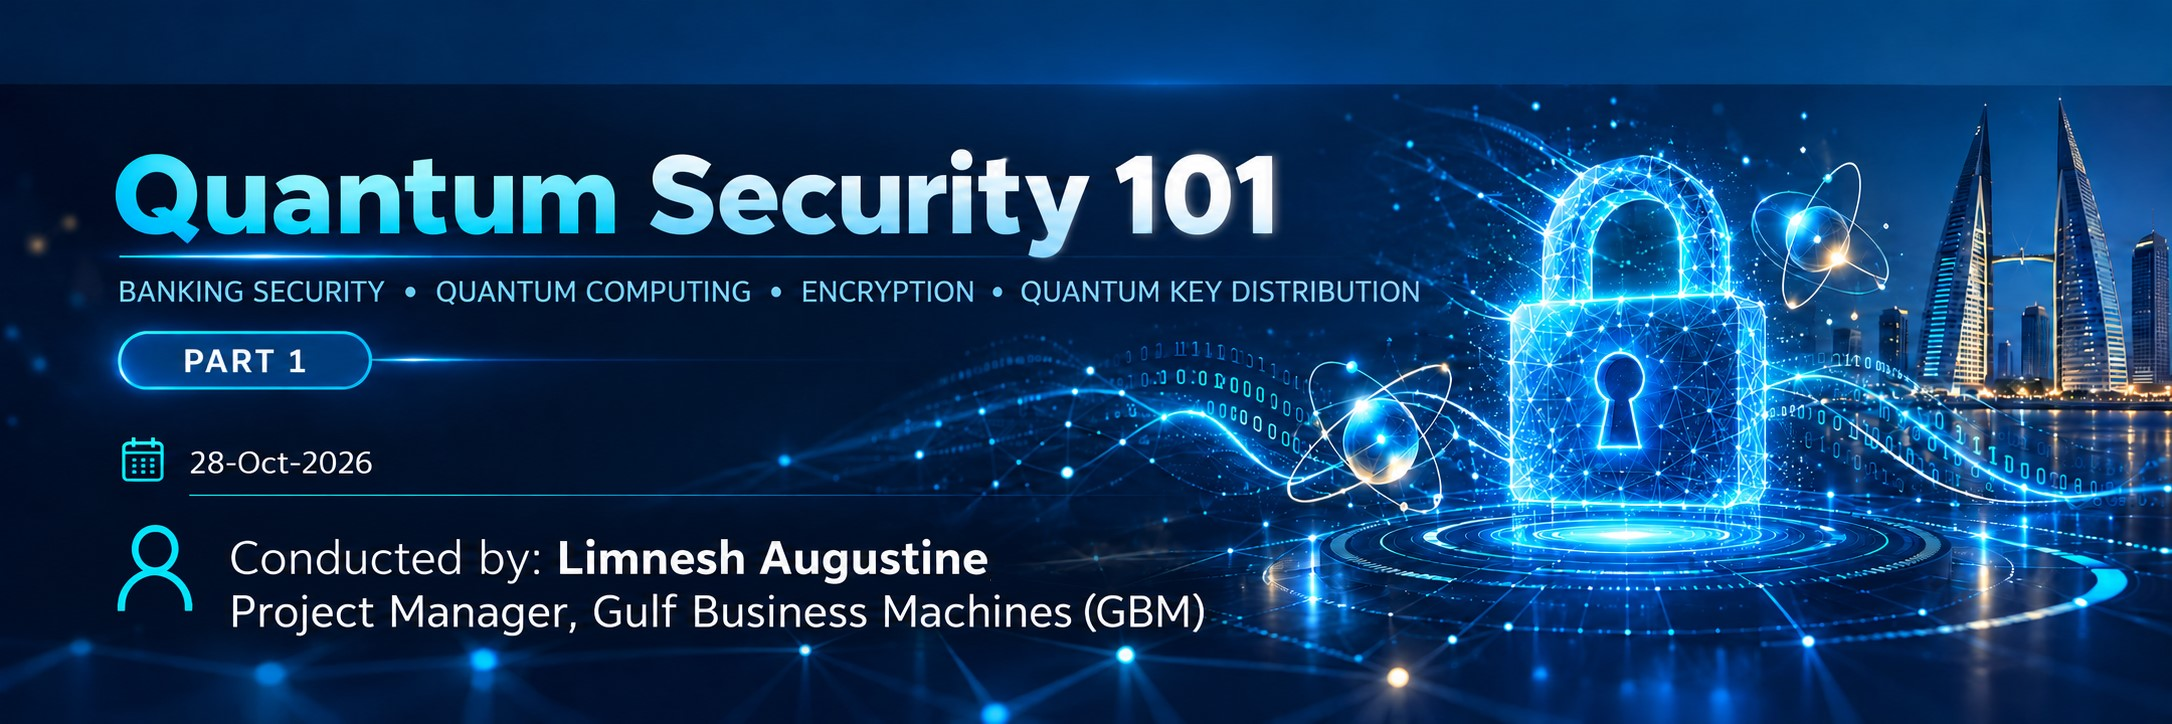
# PART 1 · Can Eve Read BSB’s Banking Data?
**BITEX 2026  /  BAHRAIN SAMPLE BANK (BSB)**

*An encrypted banking transaction becomes a recorded attack—and the beginning of a quantum mystery.*

> **Your mission:** You are the network security administrator for a fictional bank. Keep a banking record private as it travels from Manama to its two disaster-recovery sites—and see exactly what Eve can capture.

**🔵 LIVE** = follow along in the workshop &nbsp;&nbsp; **🟠 OPTIONAL** = explore afterward  
**⏱ 18 minutes live · Google Colab · Run cells from top to bottom**

| Stop | What you will discover |
|:--|:--|
| **A · Your bank** | Three sites, replication links, one editable record |
| **B · Protect the connection** | Authentication, public key exchange, AES encryption |
| **C · Eve’s capture** | Which values are public and which remain secret? |
| **D · Today’s security** | Tiny demonstration versus real cryptographic strength |
| **Optional lab** | RSA: a related but different quantum-vulnerable problem |

**How to use:** Read the short explanation, **predict what will happen**, then run the code. Change only values marked **✏️ YOUR TURN**. You do not need to understand every helper function to do the experiments.

---


---

## 🔵 LIVE · SETUP — One cell to prepare the lab

Run the next cell **once**. It loads the Python libraries and the small helper used to display results. The banking story begins after this; no values need changing here.


In [ ]:
# @title ⚙️ Setup — run once
# RUN FIRST — Imports and presentation helpers
import os, hmac, json
from hashlib import sha256
from math import gcd, isqrt
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from IPython.display import display, HTML

from html import escape as html_escape

def show_metrics(title, entries, note='', orange=False):
    accents = ['#80caff','#fcd34d','#76f2c0','#d4b5ff']
    cards = ''.join(f'<div style="flex:1 1 190px;border:1px solid #365275;background:#19375c;border-radius:11px;padding:15px"><div style="font-size:13px;color:#d2e3fa">{html_escape(str(k))}</div><div style="font-size:26px;font-weight:800;color:{accents[i%4]};overflow-wrap:anywhere">{html_escape(str(v))}</div></div>' for i,(k,v) in enumerate(entries))
    display(HTML(f'<div style="background:{"#2d1d11" if orange else "#102746"};padding:19px;border-radius:14px;color:white;max-width:1120px;font:15px Arial;box-sizing:border-box"><div style="font-weight:bold;font-size:20px;color:white;margin-bottom:12px">{html_escape(title)}</div><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div><div style="font-size:12px;color:#d0dfee;margin-top:12px">{html_escape(note)}</div></div>'))
# Colab files API, when present.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


---

## 🔵 LIVE · Step 1 — You are BSB’s security administrator

Bahrain Sample Bank (**BSB**) uses an **IBM i (AS/400)** system for core banking and an **Oracle** database for mobile banking. The bank replicates its data to two recovery locations.

| Site | Role | Connection in our example |
|:--|:--|:--|
| **Manama, Bahrain** | Production | Data originates here |
| **Sitra, Bahrain** | DR1 | Dedicated provider connectivity (Batelco/STC example) |
| **Dubai, UAE** | DR2 | Public-internet IPsec VPN |

**Your first task:** choose a harmless demonstration banking record. A small text value such as `49218` is enough—the encryption protects bytes regardless of what the record *means*.

**✏️ Your turn:** edit `bank_record`. Try `49218` first; later replace it with `TRANSFER-250` or another message. **Prediction:** what will Eve see if she records the connection?


In [ ]:
# LIVE — Three-site banking setup
# YOUR TURN — Edit the banking data and rerun from here.
bank_record = 'My Secret Banking Records'                      # Try any data like 'TRANSFER-250' or 'My Secret Banking Records'
sites = ['Sitra DR1', 'Dubai DR2']
psk = 'BSB-classroom-1234'               # Authentication demo ONLY; never a real PSK
site_links = {'Sitra DR1':'Dedicated Batelco / STC provider link','Dubai DR2':'Public Internet · IPsec VPN'}
rows = ''.join(f'<tr><td style="padding:10px;border-bottom:1px solid #dbe7f4">{name}</td><td style="padding:10px;border-bottom:1px solid #dbe7f4">{site_links[name]}</td></tr>' for name in sites)
display(HTML(f"""<div style="background:#eef6ff;color:#18314d;border-radius:12px;padding:20px;font:16px Arial;max-width:900px">
<b>BSB Manama · Production</b><div style="font-size:27px;margin:9px 0;font-weight:800">{html_escape(bank_record)}</div>
<div style="color:#506784;margin-bottom:12px">IBM i (AS/400) core banking + Oracle mobile-banking data. Sitra also has a public-internet VPN path to Dubai DR2 in this scenario.</div>
<table style="background:white;width:100%;border-collapse:collapse;color:#17324d"><tr><th style="padding:9px;text-align:left">DR destination</th><th style="padding:9px;text-align:left">Connection</th></tr>{rows}</table></div>"""))

---

## 🔵 LIVE · Step 2 — What does IPsec actually protect?

A third-party link is not automatically trusted. BSB therefore uses **IPsec** to protect replication over the public network. There are three separate jobs:

| Job | Student-friendly meaning | Our demonstration |
|:--|:--|:--|
| **Authenticate** | “Is this really my DR gateway?” | Small pre-shared key (PSK) proof |
| **Agree on a secret** | Both sites get the same secret **without sending it** | Diffie–Hellman (DH) |
| **Encrypt data** | Turn banking bytes into unreadable ciphertext | AES-256-GCM |

> **Important:** This is a classroom model of the key-exchange and encryption ideas, **not** a complete IKEv2/ESP implementation. In standard IKEv2, a normal authentication PSK is not an RSA key-transport secret.

**Ask the audience:** If someone records the network traffic, which of these values should remain private?


---

## 🔵 LIVE · Step 3 — Two sites calculate the *same* secret

Imagine Manama and Dubai each locking a box using their own private number. They exchange only a **public DH value**. By combining the *other side’s public value* with their *own private value*, both derive an identical shared secret.

- A **private exponent** stays inside its site.
- A **public DH value** can be seen by Eve.
- The **shared secret** is calculated independently on both ends.

The numbers below are intentionally tiny. They make the maths visible but are **not secure**.

**✏️ Your turn:** change `manama_private`, or Dubai’s entry in `peer_private`, and verify that both endpoints still agree. The real bank would **never print** the private keys or shared secret.


In [ ]:
# LIVE — Tiny Diffie–Hellman numbers are intentionally insecure
# YOUR TURN — Change the private exponents and rerun subsequent steps.
dh_p, dh_g = 467, 2
manama_private = 17                      # Try 27 or 51
peer_private = {'Sitra DR1':29, 'Dubai DR2':41}
assert all(1 < x < dh_p for x in [manama_private, *peer_private.values()])
manama_public = pow(dh_g, manama_private, dh_p)
peer_public = {name: pow(dh_g, exp, dh_p) for name,exp in peer_private.items()}
shared_at_manama = {name:pow(peer_public[name],manama_private,dh_p) for name in sites}
shared_at_peer = {name:pow(manama_public,peer_private[name],dh_p) for name in sites}
assert shared_at_manama == shared_at_peer
show_metrics('Public exchange and matching secrets', [('Manama · public',manama_public),('Manama · private (classroom)',manama_private),('Sitra · public',peer_public['Sitra DR1']),('Dubai · public',peer_public['Dubai DR2'])], 'Private exponents and shared secrets are displayed for teaching only. Never transmitted.')
for name in sites:
    print(f'{name}: private = {peer_private[name]}  |  DH secret at both ends = {shared_at_manama[name]}  |  keys match = {shared_at_manama[name]==shared_at_peer[name]}')

---

## 🔵 LIVE · Step 4 — Turn the shared secret into an AES key

DH gives the two gateways matching secret material, but not a ready-made packet-encryption key. Key derivation mixes that secret with public handshake values and produces key bytes of the right length.

**Notice:** the two sites compute the same key even though the key itself is never sent over the link.

The following helper imitates the *idea* of an IKEv2-style derivation using HMAC-SHA256. It is intentionally shorter than the real protocol. Just run it—there is no need to edit the helper.


In [ ]:
# LIVE — Key derivation helpers (IKEv2-inspired HMAC-SHA256)
def prf_plus(key, seed, size):
    result, previous, counter = b'', b'', 1
    while len(result) < size:
        previous = hmac.new(key, previous + seed + bytes([counter]), sha256).digest()
        result += previous
        counter += 1
    return result[:size]

def derive_data_key(shared_secret, ni, nr, spi_i, spi_r):
    shared_bytes = shared_secret.to_bytes(2, 'big')   # p=467 for this classroom example
    skeyseed = hmac.new(ni + nr, shared_bytes, sha256).digest()
    sk_d = prf_plus(skeyseed, ni + nr + spi_i + spi_r, 32*7)[:32]
    return prf_plus(sk_d, ni + nr, 64)[:32]

# Prepare two independent simulated handshakes
recordings = {}
sender_keys = {}
receiver_keys = {}
for site in sites:
    ni, nr, spi_i, spi_r = os.urandom(16), os.urandom(16), os.urandom(8), os.urandom(8)
    handshake = (str(manama_public)+'|'+str(peer_public[site])).encode()+ni+nr
    sender_auth = hmac.new(psk.encode(),handshake,sha256).digest()
    receiver_auth = hmac.new(psk.encode(),handshake,sha256).digest()
    assert hmac.compare_digest(sender_auth, receiver_auth)
    sender_keys[site] = derive_data_key(shared_at_manama[site],ni,nr,spi_i,spi_r)
    receiver_keys[site] = derive_data_key(shared_at_peer[site],ni,nr,spi_i,spi_r)
    assert sender_keys[site] == receiver_keys[site]
    recordings[site] = dict(ni=ni,nr=nr,spi_i=spi_i,spi_r=spi_r)
print('Authentication demonstration: passed for both DR sites')
print('Sender and receiver AES-256 keys match at each site.')

---

## 🔵 LIVE · Step 5 — Encrypt and replicate the banking record

Now Manama encrypts the chosen record before sending it to Sitra and Dubai. **AES-GCM** produces ciphertext plus an authentication tag. The destination uses its matching key to recover the original record.

**Look for three different views:**

1. **Before sending:** BSB’s original record (`49218`, unless you edited it).
2. **On the network:** hexadecimal ciphertext, nonce and tag—not readable banking data.
3. **At the DR site:** the decrypted original record.

**Prediction:** will Sitra’s and Dubai’s ciphertext be identical? They use separate keys and fresh random nonces, so **not necessarily**, even for the same record.


In [ ]:
# LIVE — Encrypt genuine bytes using AES-256-GCM
for site in sites:
    nonce = os.urandom(12)
    ct = AESGCM(sender_keys[site]).encrypt(nonce,bank_record.encode(),site.encode())
    received = AESGCM(receiver_keys[site]).decrypt(nonce,ct,site.encode()).decode()
    recordings[site].update(nonce=nonce,ciphertext=ct)
    assert received == bank_record
    show_metrics('Manama → '+site, [('Original record',bank_record),('Ciphertext (hex)',ct[:-16].hex()),('GCM authentication tag',ct[-16:].hex()),('Decrypted at DR',received)], 'New ciphertext is generated on every run. The AES key is never inside the transmitted packet.')

---

## 🔵 LIVE · Step 6 — Now imagine Eve is recording the network

Eve has access to the network path, so she can capture **public DH values**, handshake randomness, and the **encrypted packet**. She does *not* receive Manama’s private DH exponent, the shared secret or the AES key.

| Eve can record | Eve cannot directly read from the network |
|:--|:--|
| Public DH exchange | Private DH exponent |
| Nonce, public handshake values | Derived shared secret |
| AES ciphertext and authentication tag | Plaintext banking record |

**Ask the audience:** Is the bank safe merely because Eve cannot decrypt it **today**?


In [ ]:
# LIVE — Eve copies public data and the encrypted packet
site = 'Dubai DR2'
eve_capture = {'p':dh_p,'g':dh_g,'manama_pub':manama_public,
               'dr_pub':peer_public[site],'destination':site,**recordings[site]}
show_metrics('Eve’s capture · Dubai DR2', [('Manama public',eve_capture['manama_pub']),('Dubai public',eve_capture['dr_pub']),('Ciphertext (hex)',eve_capture['ciphertext'][:-16].hex()),('Nonce (hex)',eve_capture['nonce'].hex())], 'Neither DH private exponent, shared secret, PSK nor AES traffic key is recorded.')

---

## 🔵 LIVE · Step 7 — Classical attack: break our *toy* key exchange

Our intentionally small DH group makes a simple attack possible: Eve guesses private exponents until a guess reproduces Manama’s **public value**. The number of guesses is counted honestly by the program.

> This is a **discrete-logarithm problem**, not RSA prime factorization. The toy example is breakable in seconds because its parameters are tiny.

**✏️ Your turn:** change `manama_private` in Step 3, then rerun Steps 3–7. Does the search need a different number of guesses?


In [ ]:
# LIVE — Classical discrete logarithm, not RSA factoring
steps, recovered_private = 0, None
for guess in range(1,eve_capture['p']):
    steps += 1
    if pow(eve_capture['g'],guess,eve_capture['p'])==eve_capture['manama_pub']:
        recovered_private = guess
        break
assert recovered_private is not None
recovered_shared = pow(eve_capture['dr_pub'],recovered_private,eve_capture['p'])
show_metrics('Toy DH key recovery', [('Classical guesses',steps),('Recovered exponent',recovered_private),('Recovered shared secret',recovered_shared)],'This works quickly only because we used a tiny, insecure 9-bit DH prime.')

---

## 🔵 LIVE · Step 8 — Eve reads the recorded banking record

Once Eve knows a suitable private exponent, she reconstructs the DH shared secret, derives the same **AES-GCM key**, and opens the recorded packet. AES itself was not broken; the *key establishment* was too weak.

**Watch the output:** the recovered value should match `bank_record` from Step 1.

> **Teaching point:** For real DH/ECDH parameters, this classical guessing method is not practical. Next we compare the scale.


In [ ]:
# LIVE — Eve decrypts using only the capture and the recovered exponent
eve_key = derive_data_key(recovered_shared,eve_capture['ni'],eve_capture['nr'],eve_capture['spi_i'],eve_capture['spi_r'])
recovered_message = AESGCM(eve_key).decrypt(eve_capture['nonce'],eve_capture['ciphertext'],eve_capture['destination'].encode()).decode()
assert recovered_message==bank_record
show_metrics('Eve successfully recovers the demonstration data',[('Recovered BSB record',recovered_message),('Encryption','AES-256-GCM'),('Attack','Toy DH discrete logarithm')], 'Real-world IKEv2 DH/ECDH groups are vastly stronger against classical attacks.')

---

## 🔵 LIVE · Step 9 — Why this does not work against modern keys today

A toy number such as `467` is nowhere near modern DH/ECDH strength. A typical modern 128-bit *classical security level* corresponds to an enormous abstract work factor.

Compare a hypothetical **4-core Intel i7 laptop** with an extremely generous **exascale-class supercomputer** work rate. The headline is in **billions of years**.

**✏️ Your turn:** edit the assumed operations-per-second rates. **Caution:** these are illustrative *equivalent attack-work units*, not measured discrete-log cracking speeds or real supercomputer FLOPS benchmarks.

**Question:** Does strong AES alone guarantee that an intercepted session can never be decrypted? Not if the way its keys were established becomes vulnerable.


In [ ]:

# 🔵 LIVE — DH-2048: Classical Attack-Work Illustration
# NOT measured cryptographic cracking speeds

# ✏️ YOUR TURN — Adjust hypothetical work rates
classical_work_bits = 112  # Finite-field DH-2048
laptop_work_per_second = 10**9
supercomputer_work_per_second = 10**18
work_per_second = 10**15  # Retained for later cells

seconds_per_year = 365.25 * 24 * 3600
total_work = 2**classical_work_bits

# Calculate years
years = total_work / work_per_second / seconds_per_year
laptop_years = total_work / laptop_work_per_second / seconds_per_year
supercomputer_years = total_work / supercomputer_work_per_second / seconds_per_year

# Preserve existing variables for later cells
laptop_billions = laptop_years / 1e9
supercomputer_billions = supercomputer_years / 1e9

# Display each result using a readable unit
show_metrics(
    'DH-2048 · Classical Attack-Work Illustration',
    [
        (
            'Laptop · hypothetical rate',
            f'{laptop_billions:,.0f} BILLION YEARS'
        ),
        (
            'Exascale · hypothetical rate',
            f'{supercomputer_years / 1e6:,.0f} MILLION YEARS'
        )
    ],
    'Finite-field DH-2048: approximately 112-bit classical '
    'security. Assumed 10^9 versus 10^18 abstract work '
    'units per second. These are illustrative equivalent-work '
    'calculations, not actual discrete-logarithm cracking '
    'benchmarks or hardware performance predictions.'
)


---

## 🔵 LIVE · Step 10 — Save Eve’s recording for the quantum chapter

Today, Eve keeps the encrypted packet—even though real-world classical key recovery would be infeasible. In **Notebook 2** we use this **same capture** to demonstrate how a future quantum attack threatens ordinary DH/ECDH key agreement.

Run the next cell and keep **`bsb_dubai_capture.json`**. It contains the public handshake and ciphertext, **not** Manama’s private key.

**Bridge to Part 2:** *If Eve cannot read the archive today, could a different kind of computer change the answer later?*


In [ ]:
# LIVE — Download only public information + captured ciphertext
# One click downloads the JSON into your computer for Notebook 2.
capture_data={k:(v.hex() if isinstance(v,bytes) else v) for k,v in eve_capture.items()}
capture_filename='bsb_dubai_capture.json'
with open(capture_filename,'w',encoding='utf-8') as f: json.dump(capture_data,f,indent=2)
print('Saved:',capture_filename)
if colab_files is not None:
    colab_files.download(capture_filename)
else:
    print('Local Jupyter: find the file in the notebook working folder.')

---

## 🟠 OPTIONAL · Extra A — RSA: a different public-key lock

RSA is another example of classical public-key cryptography. Its security is related to the difficulty of **factoring** a large number built from two primes. That is **not** how our ordinary IKEv2 DH exchange works.

For an approachable arithmetic example, choose `p_demo = 11` and `q_demo = 17`, so the public modulus is `187`. The program computes an RSA example and demonstrates why learning the prime factors matters.

**✏️ Your turn:** try other small primes and examine the public and private exponents. Do not use these numbers to secure any real data.


In [ ]:
# ORANGE OPTIONAL — RSA public key and classical factoring
# YOUR TURN — Change p_demo and q_demo to other primes.
p_demo, q_demo = 11, 17
e_demo = 3
rsa_seed = 42
n_demo = p_demo*q_demo
phi_demo = (p_demo-1)*(q_demo-1)
assert gcd(e_demo,phi_demo)==1 and 0 <= rsa_seed < n_demo
private_d=pow(e_demo,-1,phi_demo)
wrapped_seed=pow(rsa_seed,e_demo,n_demo)
checks=0
for trial in range(2,isqrt(n_demo)+1):
    checks+=1
    if n_demo%trial==0:
        factor_1,factor_2=trial,n_demo//trial
        break
else: raise ValueError('Factor not found')
eve_d=pow(e_demo,-1,(factor_1-1)*(factor_2-1))
eve_seed=pow(wrapped_seed,eve_d,n_demo)
show_metrics('RSA classroom example', [('Public key',str((n_demo,e_demo))),('Private exponent (teaching)',private_d),('Classical trial divisions',checks),('Recovered secret number',eve_seed)], 'Textbook RSA with tiny numbers; not real IPsec key exchange.',orange=True)

---

## 🟠 OPTIONAL · Extra B — How large is RSA-2048?

RSA-2048 is considered to offer roughly **112 bits of classical security** under published estimates. The next calculation deliberately assumes a simple abstract work rate to illustrate the scale.

**Important:** a General Number Field Sieve attack is not a loop of identical divisions, and published security-strength numbers are not literal measured operation counts. Treat the displayed “years” as a **teaching comparison**, not a prediction of a real attack duration.


In [ ]:
# ORANGE OPTIONAL — Work-rate comparison, not GNFS measured run time
rsa_security_bits=112
work_per_second=10**15
seconds=(2**rsa_security_bits)/work_per_second
rsa_laptop_billion=(2**rsa_security_bits)/laptop_work_per_second/seconds_per_year/1e9
rsa_super_billion=(2**rsa_security_bits)/supercomputer_work_per_second/seconds_per_year/1e9
# Display each result using a readable unit
show_metrics(
    'DH-2048 · Classical Attack-Work Illustration',
    [
        (
            'Laptop · hypothetical rate',
            f'{laptop_billions:,.0f} BILLION YEARS'
        ),
        (
            'Exascale · hypothetical rate',
            f'{supercomputer_years / 1e6:,.0f} MILLION YEARS'
        )
    ],
    'Finite-field DH-2048: approximately 112-bit classical '
    'security. Assumed 10^9 versus 10^18 abstract work '
    'units per second. These are illustrative equivalent-work '
    'calculations, not actual discrete-logarithm cracking '
    'benchmarks or hardware performance predictions.'
)


### Takeaways to remember

- **IPsec can use strong encryption while still depending on a quantum-vulnerable key agreement.**
- In this demonstration, **DH established secret material**, **AES protected the record**, and **Eve captured public values plus ciphertext**.
- The toy example breaks classically only because its DH group is tiny. Real DH/ECDH is designed to resist known *classical* attacks.
- **RSA factoring and DH discrete logarithms are different problems.** Shor’s quantum algorithms threaten both, in different ways.

**Next → Part 2: From Bits to Qubits.** We will first learn what makes a quantum computer different, then return to Eve’s recorded BSB packet.

**Further reading:** [RFC 7296 (IKEv2)](https://www.rfc-editor.org/rfc/rfc7296.html) · [RFC 8784 (post-quantum preshared keys for IKEv2)](https://www.rfc-editor.org/rfc/rfc8784.html)
